## GMMM model with EM Algorithm

In [2]:
from random import uniform, seed
from math import log
import random
import numpy as np
import matplotlib.pyplot as plt

seed(42)
random.seed(42)
np.random.seed(42)

### Marsaglia Polar method (Box-Muller method)

$$
X\sim\mathcal N(\mu,\sigma^2)
$$

$$
s = u_1^2 + u_2^2
$$

$$
k = \sqrt{\frac{-2\ln(s)}{s}}
$$

$$
x_1 = \mu + \sigma u_1 k
$$

In [3]:
def gaussian(mu, sigma, n):
    g = []

    while len(g) < n:
        u1 = uniform(-1, 1)
        u2 = uniform(-1, 1)
        s = u1 * u1 + u2 * u2

        if 0 < s < 1:
            k = (-2 * log(s) / s) ** 0.5
            g.append(mu + sigma * u1 * k)

            if len(g) < n:
                g.append(mu + sigma * u2 * k)

    return g

### Defining the synthetic dataset

In [4]:
n = 10000
case = 1

means_class1 = [[2, 2], [6, 3], [4, 7]]
means_class2 = [[9, 8], [12, 10], [14, 6]]

weights_class1 = [0.40, 0.35, 0.25]
weights_class2 = [0.30, 0.40, 0.30]

isotropic_cov = np.eye(2)


def generate_isotropic(mu, sigma, N):
    x1 = gaussian(mu[0], sigma, N)
    x2 = gaussian(mu[1], sigma, N)
    return np.column_stack((x1, x2))


### Choosing a mixture component


In [6]:
def generate_data(n, weights, means, case):
    if case != 1:
        raise ValueError("This code is for isotropic covariance only.")

    component_counts = [0, 0, 0]

    for _ in range(n):
        u = random.random()

        if u < weights[0]:
            component_counts[0] += 1
        elif u < weights[0] + weights[1]:
            component_counts[1] += 1
        else:
            component_counts[2] += 1

    c1 = generate_isotropic(means[0], 1, component_counts[0])
    c2 = generate_isotropic(means[1], 1, component_counts[1])
    c3 = generate_isotropic(means[2], 1, component_counts[2])

    return c1, c2, c3

### Plot the clusters

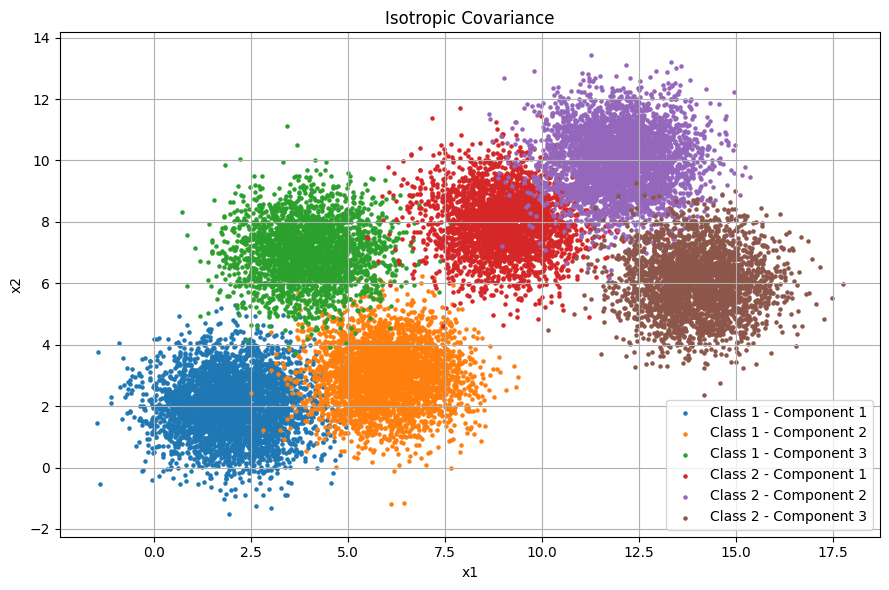

Class 1 points: 10000
Class 2 points: 10000


In [7]:
title = "Isotropic Covariance"

c1_component1, c1_component2, c1_component3 = generate_data(
    n, weights_class1, means_class1, case
)

c2_component1, c2_component2, c2_component3 = generate_data(
    n, weights_class2, means_class2, case
)

class1 = np.vstack((
    c1_component1, c1_component2, c1_component3
))

class2 = np.vstack((
    c2_component1, c2_component2, c2_component3
))

plt.figure(figsize=(9, 6))

components = [
    (c1_component1, "Class 1 - Component 1"),
    (c1_component2, "Class 1 - Component 2"),
    (c1_component3, "Class 1 - Component 3"),
    (c2_component1, "Class 2 - Component 1"),
    (c2_component2, "Class 2 - Component 2"),
    (c2_component3, "Class 2 - Component 3")
]

for data, label in components:
    plt.scatter(data[:, 0], data[:, 1], s=5, label=label)

plt.title(title)
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("Class 1 points:", len(class1))
print("Class 2 points:", len(class2))

### Splitting the dataset

In [8]:
def split_data(data):
    indices = np.random.permutation(len(data))
    split_index = int(0.8 * len(data))
    return data[indices[:split_index]], data[indices[split_index:]]


train1, test1 = split_data(class1)
train2, test2 = split_data(class2)

print("Class 1 training:", len(train1))
print("Class 1 testing:", len(test1))
print("Class 2 training:", len(train2))
print("Class 2 testing:", len(test2))

Class 1 training: 8000
Class 1 testing: 2000
Class 2 training: 8000
Class 2 testing: 2000


### Guassian log density
$$
\begin{aligned}
\ln \mathcal N(\mathbf x\mid\boldsymbol\mu,\sigma^2 \mathbf I)
=-\frac12\left[
D\ln(2\pi\sigma^2)
+\frac{\|\mathbf x-\boldsymbol\mu\|^2}{\sigma^2}
\right]
\end{aligned}
$$

In [10]:
K = 3
EPS = 1e-10
MAX_ITER = 100
TOL = 1e-5


def log_gaussian(X, mean, variance):
    D = X.shape[1]
    variance = max(float(variance), EPS)
    diff = X - mean

    return -0.5 * (
        D * np.log(2 * np.pi * variance)
        + np.sum(diff ** 2, axis=1) / variance
    )

def log_sum_exp(values):
    maximum = np.max(values, axis=1, keepdims=True)
    return maximum[:, 0] + np.log(
        np.sum(np.exp(values - maximum), axis=1)
    )


### EM Algorithm


1.   Initialize means, variances and weights
2.   E-step: Calculate responsibilities
$$
\gamma_{nk} = \frac{\pi_k \mathcal N(\mathbf x_n \mid \boldsymbol\mu_k, \sigma_k^2 \mathbf I)}{\sum_j \pi_j \mathcal N(\mathbf x_n \mid \boldsymbol\mu_j, \sigma_j^2 \mathbf I)}
$$
3.   M-step: Update weights, means and variances
$$
N_k = \sum_{n=1}^{N} \gamma_{nk}
$$

$$
\pi_k = \frac{N_k}{N}
$$

$$
\boldsymbol\mu_k = \frac{1}{N_k} \sum_{n=1}^{N} \gamma_{nk} \mathbf x_n
$$

$$
\sigma_k^2 = \frac{1}{D N_k} \sum_{n=1}^{N} \gamma_{nk} \|\mathbf x_n - \boldsymbol\mu_k\|^2
$$

4.   Recalculate likelihood using updated parameters

$$
\mathcal L(\theta) = \sum_{n=1}^{N} \ln p(\mathbf x_n \mid \theta)
$$




In [11]:
def GMM(data, K):
    N, D = data.shape

    # Initialize means, variances and weights
    indices = np.random.choice(N, K, replace=False)
    means = data[indices].copy()

    initial_variance = np.var(data, axis=0).mean()
    variances = np.full(K, max(initial_variance, EPS))
    weights = np.ones(K) / K

    previous_likelihood = -np.inf

    for iteration in range(MAX_ITER):

        # E-step: Calculate responsibilities
        log_p = np.zeros((N, K))

        for k in range(K):
            log_p[:, k] = (
                np.log(max(weights[k], EPS))
                + log_gaussian(data, means[k], variances[k])
            )

        log_total = log_sum_exp(log_p)
        responsibilities = np.exp(log_p - log_total[:, None])

        # M-step: Update weights and means
        Nk = np.maximum(responsibilities.sum(axis=0), EPS)

        weights = Nk / N
        means = (responsibilities.T @ data) / Nk[:, None]

        # M-step: Update isotropic variances
        for k in range(K):
            diff = data - means[k]

            variances[k] = max(
                np.sum(
                    responsibilities[:, k]
                    * np.sum(diff ** 2, axis=1)
                ) / (D * Nk[k]),
                EPS
            )

        # Recalculate likelihood using updated parameters
        updated_log_p = np.zeros((N, K))

        for k in range(K):
            updated_log_p[:, k] = (
                np.log(max(weights[k], EPS))
                + log_gaussian(data, means[k], variances[k])
            )

        likelihood = np.sum(log_sum_exp(updated_log_p))

        if np.isfinite(previous_likelihood):
            if abs(likelihood - previous_likelihood) < (
                TOL * (1 + abs(previous_likelihood))
            ):
                break

        previous_likelihood = likelihood

    return weights, means, variances


model1 = GMM(train1, K)
model2 = GMM(train2, K)

print("\nCLASS 1 GMM")
print("Weights:", model1[0])
print("Means:\n", model1[1])
print("Variances:", model1[2])

print("\nCLASS 2 GMM")
print("Weights:", model2[0])
print("Means:\n", model2[1])
print("Variances:", model2[2])


CLASS 1 GMM
Weights: [0.34594483 0.39510303 0.25895214]
Means:
 [[5.98900751 3.01566225]
 [1.99756745 2.00080276]
 [3.97642893 7.02025673]]
Variances: [0.99879069 1.01095541 0.97627328]

CLASS 2 GMM
Weights: [0.29871083 0.31043931 0.39084986]
Means:
 [[13.99824514  6.03316609]
 [ 9.02592193  8.00937535]
 [12.01438797 10.0214234 ]]
Variances: [0.99843575 1.03552863 0.97499885]


### Testing

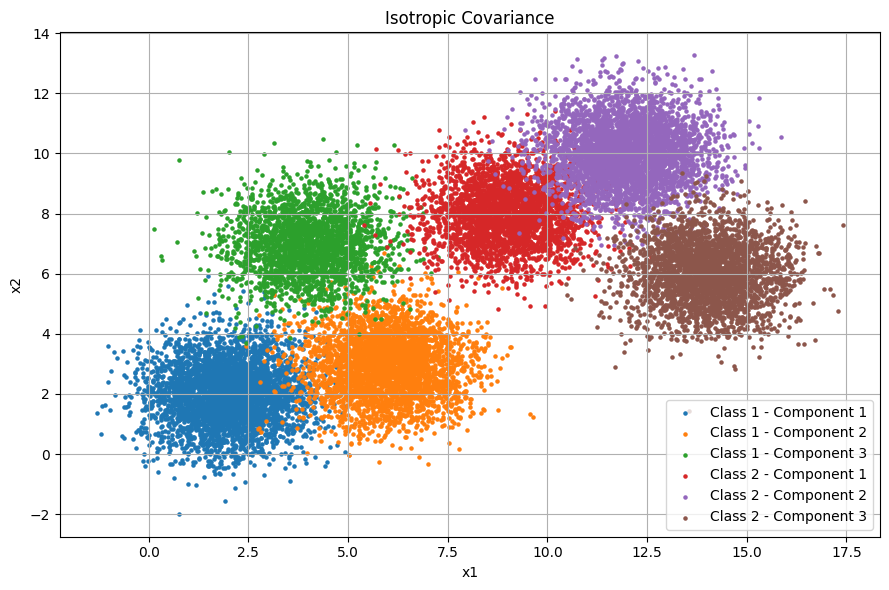

Class 1 points: 10000
Class 2 points: 10000
Class 1 training: 8000
Class 1 testing: 2000
Class 2 training: 8000
Class 2 testing: 2000

CLASS 1 GMM
Weights: [0.24741994 0.40434689 0.34823316]
Means:
 [[4.00814425 6.985677  ]
 [2.0081349  2.00272946]
 [5.99290376 2.97218137]]
Variances: [1.0347595  0.98572572 1.00165034]

CLASS 2 GMM
Weights: [0.40597335 0.30013983 0.29388682]
Means:
 [[11.97938511 10.02773906]
 [14.02995064  6.0212452 ]
 [ 8.9699203   8.01019825]]
Variances: [0.98948169 0.99780006 0.98934702]

Overall GMM Classification Results
Correct predictions: 3996
Total test samples: 4000
Accuracy: 99.9 %

Confusion Matrix:
[[1997    3]
 [   1 1999]]


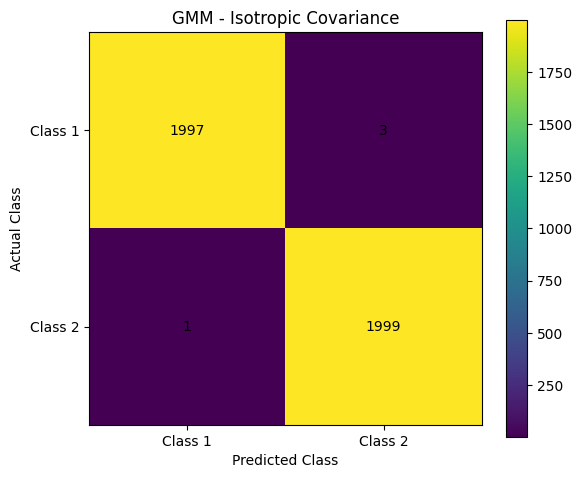

In [5]:
def GMM_log_probability(data, model):
    weights, means, variances = model
    log_p = np.zeros((len(data), len(weights)))

    for k in range(len(weights)):
        log_p[:, k] = (
            np.log(max(weights[k], EPS))
            + log_gaussian(data, means[k], variances[k])
        )

    return log_sum_exp(log_p)


X_test = np.vstack((test1, test2))

true_labels = np.concatenate((
    np.ones(len(test1), dtype=int),
    np.full(len(test2), 2, dtype=int)
))

log_p1 = GMM_log_probability(X_test, model1)
log_p2 = GMM_log_probability(X_test, model2)

predicted_labels = np.where(log_p1 > log_p2, 1, 2)


correct = np.sum(predicted_labels == true_labels)
total = len(true_labels)
accuracy = 100 * correct / total

print("\nOverall GMM Classification Results")
print("Correct predictions:", correct)
print("Total test samples:", total)
print("Accuracy:", round(accuracy, 2), "%")

cm = np.zeros((2, 2), dtype=int)

for actual, predicted in zip(true_labels, predicted_labels):
    cm[actual - 1, predicted - 1] += 1

print("\nConfusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation="nearest")
plt.xticks([0, 1], ["Class 1", "Class 2"])
plt.yticks([0, 1], ["Class 1", "Class 2"])
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("GMM - Isotropic Covariance")

for i in range(2):
    for j in range(2):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center")

plt.colorbar()
plt.tight_layout()
plt.show()
